# QC Threshold Calibration

Notebook ini mengkalibrasi gate quality control inference untuk ketiga situs (konjungtiva, palm, nail) terhadap distribusi data training. Prinsipnya, foto training adalah contoh foto yang baik sehingga tidak boleh ditolak oleh gate inference, sementara foto yang jelek atau salah objek tetap harus ditolak. Seluruh metrik diukur lewat fungsi `_measure` pada `app/predict*.py`, yaitu jalur yang persis sama dengan endpoint inference, lalu batas gate diturunkan dari persentil set positif dan dievaluasi terhadap set negatif.

## Setup

Fungsi reusable berada di `src/common/qc_calibration.py`. Hasil pengukuran disimpan ke `outputs/qc_calibration` dan dipakai ulang bila sudah ada, kecuali `RECOMPUTE` diset `True`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / "configs").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from app import predict, predict_nail, predict_palm
from configs.paths import OUTPUTS
from src.common import qc, qc_calibration

OUTPUT_DIR = OUTPUTS / "qc_calibration"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RECOMPUTE = False
NEGATIVE_SAMPLE = 40
CROSS_SAMPLE = 60
SEED = 42

## Measurement Functions

Setiap situs memakai fungsi `_measure` miliknya dan loader citra yang sama dengan endpoint inference: konjungtiva dan nail memakai PIL dengan koreksi EXIF, palm memakai cv2 tanpa koreksi EXIF.

In [2]:
conjunctiva_resources = predict._load_resources("cpu")

MEASURE = {
    "conjunctiva": lambda rgb: predict._measure(rgb, conjunctiva_resources, "cpu")[2],
    "palm": lambda rgb: predict_palm._measure(rgb)["quality"],
    "nail": lambda rgb: predict_nail._measure(rgb)[2],
}
EXIF = {"conjunctiva": True, "palm": False, "nail": True}

## Positive Sets

Set positif adalah input mentah data training yang setara dengan foto unggahan pengguna. Konjungtiva memakai foto mata utuh Eyes-Defy (CP-AnemiC sudah berupa crop ROI sehingga tidak melewati jalur segmentasi), palm memakai frame terpilih dari video Valles-Coral, dan nail memakai foto jari mentah Valles-Coral.

In [3]:
conjunctiva_manifest = pd.read_csv(OUTPUTS / "conjunctiva" / "manifest.csv")
conjunctiva_manifest = conjunctiva_manifest[conjunctiva_manifest["dataset"] == "eyes_defy"]
palm_frames = pd.read_csv(OUTPUTS / "palm" / "frame_qc.csv")
nail_manifest = pd.read_csv(OUTPUTS / "nail" / "manifest.csv")

POSITIVE_PATHS = {
    "conjunctiva": list(zip(conjunctiva_manifest["uid"], conjunctiva_manifest["raw_path"])),
    "palm": list(zip(palm_frames["uid"], palm_frames["frame_path"])),
    "nail": list(zip(nail_manifest["uid"], nail_manifest["raw_path"])),
}
{site: len(paths) for site, paths in POSITIVE_PATHS.items()}

{'conjunctiva': 215, 'palm': 809, 'nail': 803}

In [4]:
def loaders(site, pairs, exif_site=None):
    exif = EXIF[exif_site or site]
    return [(uid, (lambda p=path, e=exif: qc_calibration.load_rgb(p, e))) for uid, path in pairs]


def measure_site(site):
    cache = OUTPUT_DIR / f"{site}_measurements.csv"
    if cache.exists() and not RECOMPUTE:
        return pd.read_csv(cache)
    rng = np.random.default_rng(SEED)
    frames = [qc_calibration.measure_images(loaders(site, POSITIVE_PATHS[site]), MEASURE[site], "positive")]

    sample_index = rng.choice(len(POSITIVE_PATHS[site]), size=min(NEGATIVE_SAMPLE, len(POSITIVE_PATHS[site])), replace=False)
    sampled = [POSITIVE_PATHS[site][i] for i in sample_index]
    frames.append(qc_calibration.measure_negatives(loaders(site, sampled), MEASURE[site], seed=SEED))

    for other in POSITIVE_PATHS:
        if other == site:
            continue
        other_index = rng.choice(len(POSITIVE_PATHS[other]), size=min(CROSS_SAMPLE, len(POSITIVE_PATHS[other])), replace=False)
        other_pairs = [POSITIVE_PATHS[other][i] for i in other_index]
        frames.append(qc_calibration.measure_images(loaders(site, other_pairs, exif_site=site), MEASURE[site], f"cross_{other}"))

    real_world_dir = OUTPUT_DIR / "real_world" / site
    if real_world_dir.is_dir():
        real_pairs = [(path.stem, path) for path in sorted(real_world_dir.iterdir()) if path.suffix.lower() in {".jpg", ".jpeg", ".png"}]
        frames.append(qc_calibration.measure_images(loaders(site, real_pairs), MEASURE[site], "real_world"))

    measurements = pd.concat(frames, ignore_index=True)
    measurements.to_csv(cache, index=False)
    return measurements


MEASUREMENTS = {site: measure_site(site) for site in POSITIVE_PATHS}
{site: frame["source"].value_counts().to_dict() for site, frame in MEASUREMENTS.items()}

{'conjunctiva': {'positive': 215,
  'cross_palm': 60,
  'cross_nail': 60,
  'neg_blur': 40,
  'neg_dark': 40,
  'neg_overexposed': 40,
  'neg_tiny': 40,
  'neg_corner_crop': 40,
  'neg_flat_beige': 40,
  'neg_wood_texture': 40,
  'neg_noise': 40,
  'real_world': 3},
 'palm': {'positive': 809,
  'cross_conjunctiva': 60,
  'cross_nail': 60,
  'neg_blur': 40,
  'neg_dark': 40,
  'neg_overexposed': 40,
  'neg_tiny': 40,
  'neg_corner_crop': 40,
  'neg_flat_beige': 40,
  'neg_wood_texture': 40,
  'neg_noise': 40,
  'real_world': 2},
 'nail': {'positive': 803,
  'cross_conjunctiva': 60,
  'cross_palm': 60,
  'neg_blur': 40,
  'neg_dark': 40,
  'neg_overexposed': 40,
  'neg_tiny': 40,
  'neg_corner_crop': 40,
  'neg_flat_beige': 40,
  'neg_wood_texture': 40,
  'neg_noise': 40,
  'real_world': 1}}

## Current Policy Baseline

Evaluasi gate yang sedang berlaku di produksi (`configs/qc_thresholds.json` sebelum kalibrasi) terhadap seluruh set, sebagai pembanding hasil kalibrasi.

In [5]:
BASELINE = {site: qc_calibration.evaluate_policy(frame, qc.load_site_gates(site)) for site, frame in MEASUREMENTS.items()}
for site, evaluated in BASELINE.items():
    print(site)
    print(qc_calibration.summarize_policy(evaluated).to_string(index=False))
    print()

conjunctiva
          source   n  pass_rate                                                           top_reasons
      cross_nail  60     0.0000  blur 60, roi_coverage_low 60, roi_confidence_low 60, underexposed 59
      cross_palm  60     0.0000 blur 60, roi_too_small 60, roi_coverage_low 60, roi_confidence_low 60
        neg_blur  40     0.0000                                                               blur 40
 neg_corner_crop  40     0.0000  blur 40, roi_coverage_low 40, roi_confidence_low 39, underexposed 35
        neg_dark  40     0.0000  blur 40, underexposed 40, roi_coverage_low 40, roi_confidence_low 40
  neg_flat_beige  40     0.0000                  blur 40, underexposed 40, glare 40, roi_too_small 40
       neg_noise  40     0.0000 roi_coverage_low 40, roi_confidence_low 40, roi_off_center 29, blur 7
 neg_overexposed  40     0.0000         glare 39, roi_coverage_low 39, roi_confidence_low 37, blur 35
        neg_tiny  40     0.0000                  blur 40, underexposed

## Metric Distributions

Ringkasan persentil 0.5, median, dan 99.5 setiap metrik pada set positif, dibandingkan median setiap kategori negatif. Metrik yang memisahkan positif dan negatif dengan jelas layak dijadikan gate, metrik yang tumpang tindih tidak.

In [6]:
METRICS = ["laplacian_variance", "brightness", "glare_fraction", "roi_pixels", "components", "aspect_ratio",
           "solidity", "coverage", "centroid_offset", "segmentation_confidence", "skin_coverage",
           "finger_area_frac", "nail_area_frac"]


def distribution_table(frame):
    frame = frame[~frame["segmentation_failed"].astype(bool)]
    present = [metric for metric in METRICS if metric in frame and frame[metric].notna().any()]
    rows = {}
    for source, group in frame.groupby("source"):
        if source == "positive":
            rows[source] = {m: f"{group[m].quantile(0.005):.3g} | {group[m].median():.3g} | {group[m].quantile(0.995):.3g}" for m in present}
        else:
            rows[source] = {m: f"{group[m].median():.3g}" for m in present}
    return pd.DataFrame(rows)


for site, frame in MEASUREMENTS.items():
    print(site)
    print(distribution_table(frame).to_string())
    print()

conjunctiva
                        cross_nail cross_palm  neg_blur neg_corner_crop neg_dark neg_flat_beige neg_noise neg_overexposed neg_tiny neg_wood_texture                       positive real_world
laplacian_variance               0          0      1.61               0        0              0  3.29e+03               0        0                0              10.2 | 23.4 | 165         15
brightness                       0          0       165               0        0              0       172               0        0                0                125 | 171 | 203        215
glare_fraction                   1          1         0               1        1              1    0.0762               1        1                1                0 | 0 | 0.00442     0.0115
roi_pixels                       0          0  8.07e+05               0        0              0  3.02e+03               0        0                0  2.49e+05 | 6.41e+05 | 1.3e+06   1.67e+04
components                       0    

## Policy Rules

Batas setiap gate dinyatakan sebagai aturan. Spesifikasi `("pct", p, m)` berarti persentil `p` set positif yang dilonggarkan dengan margin relatif `m`, angka berarti batas tetap yang ditetapkan manual dengan alasan di bawah, dan gate yang tidak tercantum berarti tidak dipakai untuk situs tersebut.

Konjungtiva:
- Ketajaman, kecerahan bawah, solidity, coverage bawah, dan keyakinan segmentasi memakai persentil 0.5 set positif dengan margin, karena metrik ini memisahkan foto training dari blur, gelap, dan objek bukan mata dengan jelas.
- Solidity rendah adalah sifat anatomis konjungtiva palpebra yang berbentuk pita bulan sabit, sehingga batasnya jauh lebih rendah dari situs lain. Margin solidity 0.2 dipilih agar foto training India 060, yang secara visual valid, tetap lolos.
- Batas komponen dinaikkan ke 5 karena satu foto training valid memiliki 5 komponen, sementara fragmentasi tidak menambah daya pisah (seluruh negatif yang terfragmentasi sudah ditolak gate lain).
- Coverage atas ditetapkan 0.5, lebih longgar dari persentil 99.5 training (sekitar 0.11), karena pengguna ponsel dapat memotret lebih dekat daripada protokol Eyes-Defy.
- Glare dan kecerahan atas dipertahankan pada nilai lama karena tidak ada bukti bahwa pengetatan menambah daya pisah.

Palm:
- Foto training palm adalah frame video close-up yang sangat terang (median kecerahan 234 dan median glare 0.475), sehingga gate glare dan overexposed tidak dipakai, karena keduanya akan menolak sebagian besar data training.
- Gate jumlah komponen tidak dipakai karena mask jalur landmark pada data training sendiri terfragmentasi (median 3, maksimum 433 komponen), sehingga fragmentasi bukan tanda foto jelek pada situs ini.
- skin_coverage pada jalur skin_fallback memakai batas bawah dari persentil training dan batas atas 0.99, sehingga close-up telapak diterima sementara bidang polos berwarna kulit, foto kuku, dan foto mata ditolak.
- Ketajaman memakai margin lebih kecil (0.25) agar seluruh varian blur berat ditolak.

Nail:
- Foto training adalah ujung jari terstandar di atas permukaan gelap, sehingga ROI kuku yang valid hampir cembung sempurna (solidity di atas 0.9) dan tidak memanjang. Solidity rendah dan rasio aspek tinggi menandakan segmentasi bocor ke latar berwarna kulit, misalnya meja kayu.
- nail_area_frac dan finger_area_frac diberi batas atas tetap untuk menolak foto telapak dan bidang berwarna kulit yang terbaca seluruhnya sebagai jari.
- Glare atas ditetapkan 0.30, sama dengan batas umum konjungtiva. Tiga foto training (ID210, ID290, ID310) memiliki 41 sampai 77 persen piksel kuku yang jenuh sehingga warna kuku hilang, dan ketiganya sengaja ditolak karena masuk data training hanya karena dahulu tidak ada quality control.
- Rasio aspek atas ditetapkan 2.8 agar mencakup maksimum training (2.68, ID838 yang secara visual valid). Kebocoran segmentasi ke latar berwarna kulit terutama ditangkap oleh solidity.

In [7]:
P = lambda percentile, margin: ("pct", percentile, margin)

RULES = {
    "conjunctiva": {
        "laplacian_variance": {"min": P(0.5, 0.5)},
        "brightness": {"min": P(0.5, 0.5), "max": 245.0},
        "glare_fraction": {"max": 0.30},
        "roi_pixels": {"min": 300},
        "components": {"max": 5},
        "aspect_ratio": {"max": P(99.5, 0.3)},
        "solidity": {"min": P(0.5, 0.2)},
        "coverage": {"min": P(0.5, 0.5), "max": 0.5},
        "centroid_offset": {"max": P(99.5, 0.3)},
        "segmentation_confidence": {"min": P(0.5, 0.15)},
    },
    "palm": {
        "laplacian_variance": {"min": P(0.5, 0.25)},
        "brightness": {"min": P(0.5, 0.5)},
        "roi_pixels": {"min": 300},
        "aspect_ratio": {"max": P(99.5, 0.3)},
        "solidity": {"min": P(0.5, 0.2)},
        "coverage": {"min": P(0.5, 0.5), "max": 0.99},
        "skin_coverage": {"min": P(0.5, 0.35), "max": 0.99},
    },
    "nail": {
        "laplacian_variance": {"min": P(0.5, 0.5)},
        "brightness": {"min": P(0.5, 0.4), "max": P(99.5, 0.2)},
        "glare_fraction": {"max": 0.30},
        "roi_pixels": {"min": 300},
        "components": {"max": 3},
        "aspect_ratio": {"max": 2.8},
        "solidity": {"min": P(0.5, 0.15)},
        "finger_area_frac": {"min": P(0.5, 0.5), "max": 0.7},
        "nail_area_frac": {"min": P(0.5, 0.3), "max": 0.10},
    },
}

CALIBRATED = {
    site: qc_calibration.derive_gates(MEASUREMENTS[site][MEASUREMENTS[site]["source"] == "positive"], rules)
    for site, rules in RULES.items()
}
CALIBRATED

{'conjunctiva': {'laplacian_variance': {'min': 5.092, 'max': None},
  'brightness': {'min': 62.61, 'max': 245.0},
  'glare_fraction': {'min': None, 'max': 0.3},
  'roi_pixels': {'min': 300.0, 'max': None},
  'components': {'min': None, 'max': 5.0},
  'aspect_ratio': {'min': None, 'max': 5.283},
  'solidity': {'min': 0.17, 'max': None},
  'coverage': {'min': 0.01047, 'max': 0.5},
  'centroid_offset': {'min': None, 'max': 0.3393},
  'segmentation_confidence': {'min': 0.7532, 'max': None}},
 'palm': {'laplacian_variance': {'min': 1.764, 'max': None},
  'brightness': {'min': 107.9, 'max': None},
  'roi_pixels': {'min': 300.0, 'max': None},
  'aspect_ratio': {'min': None, 'max': 2.869},
  'solidity': {'min': 0.5986, 'max': None},
  'coverage': {'min': 0.007703, 'max': 0.99},
  'skin_coverage': {'min': 0.3995, 'max': 0.99}},
 'nail': {'laplacian_variance': {'min': 16.0, 'max': None},
  'brightness': {'min': 91.57, 'max': 240.7},
  'glare_fraction': {'min': None, 'max': 0.3},
  'roi_pixels': 

## Policy Evaluation

Tingkat lolos setiap sumber data di bawah kebijakan terkalibrasi. Targetnya set positif lolos minimal 99.5 persen per situs, dan sebagian besar kategori negatif ditolak.

In [8]:
EVALUATED = {site: qc_calibration.evaluate_policy(MEASUREMENTS[site], CALIBRATED[site]) for site in CALIBRATED}
for site, evaluated in EVALUATED.items():
    print(site)
    print(qc_calibration.summarize_policy(evaluated).to_string(index=False))
    print()

conjunctiva
          source   n  pass_rate                                                           top_reasons
      cross_nail  60        0.0  blur 60, roi_coverage_low 60, roi_confidence_low 60, underexposed 59
      cross_palm  60        0.0 blur 60, roi_too_small 60, roi_coverage_low 60, roi_confidence_low 60
        neg_blur  40        0.0                                                               blur 40
 neg_corner_crop  40        0.0  blur 40, roi_coverage_low 40, roi_confidence_low 39, underexposed 35
        neg_dark  40        0.0  blur 40, underexposed 40, roi_coverage_low 40, roi_confidence_low 40
  neg_flat_beige  40        0.0                  blur 40, underexposed 40, glare 40, roi_too_small 40
       neg_noise  40        0.0 roi_coverage_low 40, roi_confidence_low 40, roi_off_center 29, blur 7
 neg_overexposed  40        0.0         glare 39, roi_coverage_low 39, roi_confidence_low 37, blur 35
        neg_tiny  40        0.0                  blur 40, underexposed

## Rejected Training Images

Setiap foto training yang masih ditolak ditampilkan beserta alasannya untuk ditinjau satu per satu, agar terlihat apakah penolakan memang karena foto jelek atau karena batas yang keliru.

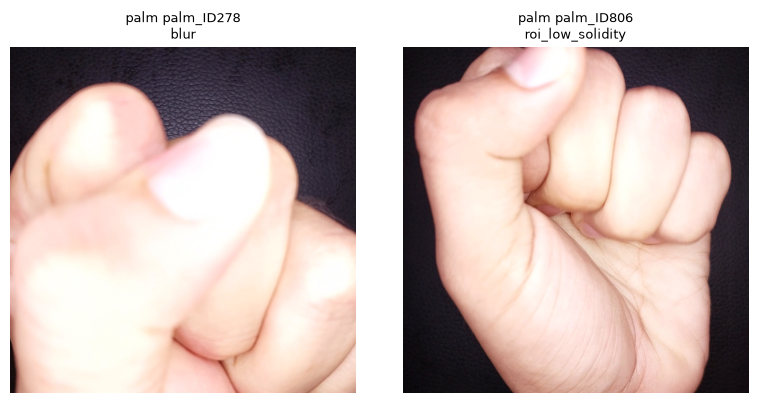

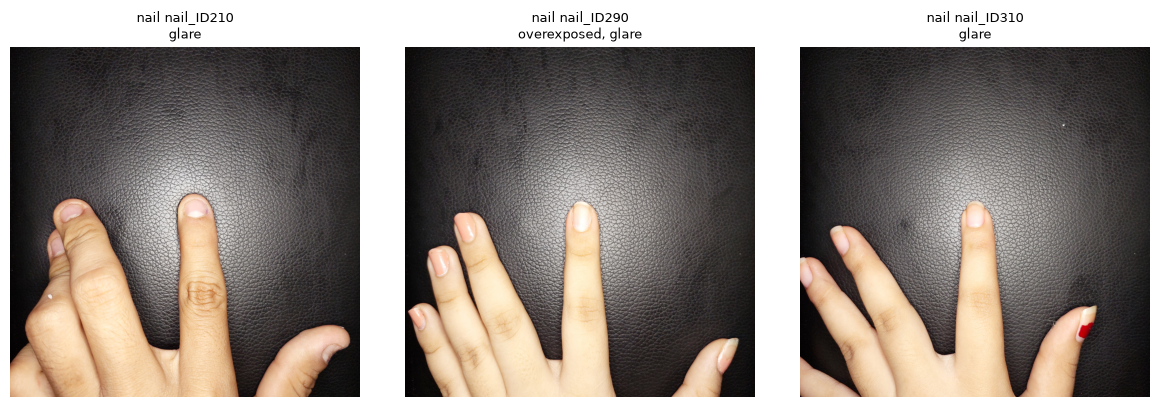

In [9]:
import matplotlib.pyplot as plt

for site, evaluated in EVALUATED.items():
    rejected = evaluated[(evaluated["source"] == "positive") & (~evaluated["passed"])]
    if rejected.empty:
        continue
    paths = dict(POSITIVE_PATHS[site])
    fig, axes = plt.subplots(1, len(rejected), figsize=(4 * len(rejected), 4), squeeze=False)
    for axis, (_, row) in zip(axes[0], rejected.iterrows()):
        axis.imshow(qc_calibration.load_rgb(paths[row["uid"]], EXIF[site]))
        axis.set_title(f"{site} {row['uid']}\n{', '.join(row['reasons'])}", fontsize=9)
        axis.axis("off")
    plt.tight_layout()
    plt.show()

## Real World Photos

Foto ponsel nyata (bukan data training) dievaluasi terpisah sebagai pemeriksaan kewajaran. Foto nail Taqi diharapkan ditolak karena segmentasinya bocor ke meja kayu berwarna kulit, sehingga ROI tidak murni kuku.

In [10]:
pd.concat([
    evaluated.loc[evaluated["source"] == "real_world", ["uid", "passed", "reasons"]].assign(site=site)
    for site, evaluated in EVALUATED.items()
], ignore_index=True)

,uid,passed,reasons,site
0,taqi_mata1,True,[],conjunctiva
1,taqi_mata2,True,[],conjunctiva
2,taqi_mata3,True,[],conjunctiva
3,taqi_telapak1,True,[],palm
4,taqi_telapak2,True,[],palm
5,taqi_telunjuk,False,[roi_low_solidity],nail


## Write Thresholds

Batas terkalibrasi ditulis ke `configs/qc_thresholds.json` beserta catatan asal-usul, lalu dibaca oleh `qc.load_site_gates` pada setiap endpoint inference.

In [11]:
provenance = {
    "notebook": "notebooks/qc_calibration.ipynb",
    "positive_sets": {
        "conjunctiva": "Eyes-Defy full eye photos",
        "palm": "Valles-Coral selected video frames",
        "nail": "Valles-Coral raw fingertip photos",
    },
    "positive_counts": {site: int((MEASUREMENTS[site]["source"] == "positive").sum()) for site in MEASUREMENTS},
    "positive_pass_rate": {
        site: round(float(evaluated.loc[evaluated["source"] == "positive", "passed"].mean()), 4)
        for site, evaluated in EVALUATED.items()
    },
    "rules": {site: {metric: {side: list(spec) if isinstance(spec, tuple) else spec for side, spec in rule.items()} for metric, rule in rules.items()} for site, rules in RULES.items()},
}
qc_calibration.write_thresholds(CALIBRATED, provenance)
qc.load_site_gates("palm")

{'laplacian_variance': {'min': 1.764, 'max': None},
 'brightness': {'min': 107.9, 'max': None},
 'roi_pixels': {'min': 300.0, 'max': None},
 'aspect_ratio': {'min': None, 'max': 2.869},
 'solidity': {'min': 0.5986, 'max': None},
 'coverage': {'min': 0.007703, 'max': 0.99},
 'skin_coverage': {'min': 0.3995, 'max': 0.99}}